# Interpretable multimodal retrieval augmented diagnosis for breast ultrasound with multinational clinical validation and reader study

*npj Digital Medicine*, 2026 - DOI [10.1038/s41746-026-03272-3](https://doi.org/10.1038/s41746-026-03272-3)

**B-RAD end-to-end inference demo.** This notebook runs the full B-RAD pipeline
on one public breast-ultrasound image and visualizes each stage:

1. **B-RAD-CLIP** - BI-RADS-aware image retrieval (top-k references).
2. **B-RAD-Det** - few-shot lesion box (green) vs. ground truth (red) + bbox Dice/IoU.
3. **B-RAD-Seg** - bbox-prompted UltraSam mask vs. ground truth + Dice/IoU.
4. **B-RAD-FULL** - region-aware BI-RADS {2,3,4,5} probability vs. ground truth.

The modules use different environments. Run this notebook in the **B-RAD-CLIP /
B-RAD-FULL** environment (torch + transformers); the segmentation cell shells out
to the **B-RAD-Seg** environment via `SEG_PY`. Set checkpoint paths, `SEG_PY`, and
`BREAST_DATA_ROOT` (folder holding the BrEaST images) through the environment
variables read in the setup cell, or edit their defaults.


## 0. Setup

root=B-RAD  device=cuda  segmentation env=ultrasam
Sample usg_0059 | malignant | GT BI-RADS 4c | 545x532


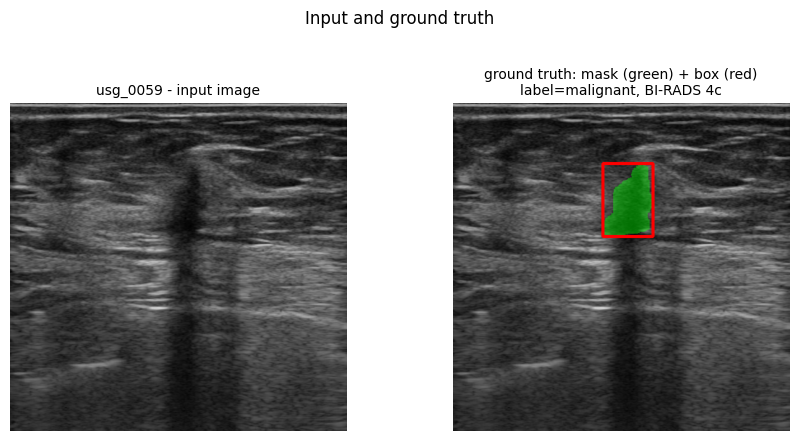

MedGemma pseudo-report:
  Ultrasonography shows an unevenly contoured lesion with blurred, ill-defined borders that appears darker than the surrounding tissue; posterior acoustic casting a dark acoustic shadow behind it, and the overlying skin appears normal.


In [1]:
import os, sys, json, ast, subprocess, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
try:
    from transformers.utils import logging as _hf; _hf.set_verbosity_error()
except Exception:
    pass

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

def _find_root(start):
    """Repository root = the folder containing B-RAD/samples/sample.csv."""
    for p in [start, *start.parents]:
        if (p / "B-RAD" / "samples" / "sample.csv").exists():
            return p
    return start


def _find_seg_python():
    """Interpreter of the B-RAD-Seg env (needs mmdet); $SEG_PY wins if set."""
    if os.environ.get("SEG_PY"):
        return os.environ["SEG_PY"]
    if any(Path(sys.prefix, "lib").glob("python*/site-packages/mmdet")):
        return sys.executable                      # this kernel already has mmdet
    roots = []
    if os.environ.get("CONDA_PREFIX"):
        roots.append(Path(os.environ["CONDA_PREFIX"]).parent)
    roots += [Path.home() / ".conda/envs", Path.home() / "anaconda3/envs",
              Path.home() / "miniconda3/envs"]
    for r in roots:
        if not r.is_dir():
            continue
        for py in sorted(r.glob("*/bin/python")):
            if any((py.parent.parent / "lib").glob("python*/site-packages/mmdet")):
                return str(py)
    return sys.executable                          # will fail loudly in the seg cell


ROOT = _find_root(Path.cwd())
PKG = ROOT / "B-RAD"   # modules + samples + scripts live here
SAMPLES = PKG / "samples"
OUT = SAMPLES / "predictions"; OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(PKG / "B-RAD-CLIP"))
sys.path.insert(0, str(PKG / "B-RAD-FULL"))  # both dirs vendor an identical brad_clip package

# --- auto-configured; set the matching env var to override any of these ---
DEVICE     = os.environ.get("DEVICE", "cuda" if __import__("torch").cuda.is_available() else "cpu")
SEG_PY     = _find_seg_python()
CLIP_CKPT  = os.environ.get("CLIP_CKPT", str(PKG / "ckpts/b_rad_clip.pt"))
FULL_CKPT  = os.environ.get("FULL_CKPT", str(PKG / "ckpts/b_rad_full.pt"))
SEG_CKPT   = os.environ.get("SEG_CKPT",  str(PKG / "ckpts/UltraSam.pth"))
DET_CKPT   = os.environ.get("DET_CKPT",  str(PKG / "ckpts/b_rad_det.pt"))
BANK       = PKG / "B-RAD-CLIP/assets/reference_bank.npz"
# Folder holding the retrieved reference images (optional: only for the gallery).
DATA_ROOT  = Path(os.environ.get("BREAST_DATA_ROOT", str(SAMPLES)))
_seg = Path(SEG_PY)
_seg_env = _seg.parents[1].name if len(_seg.parents) > 1 else SEG_PY
print(f"root={ROOT.name}  device={DEVICE}  segmentation env={_seg_env}")

DEMO_UID = os.environ.get("DEMO_UID", "usg_0059")
s = pd.read_csv(SAMPLES / "sample.csv").query("uid == @DEMO_UID").iloc[0]
IMG = SAMPLES / s.image
MASK = SAMPLES / s["mask"]
GT_BBOX = ast.literal_eval(s.gt_bbox_xyxy)
GT_BIRADS = str(s.birads)
image_rgb = cv2.cvtColor(cv2.imread(str(IMG)), cv2.COLOR_BGR2RGB)
gt_mask = cv2.imread(str(MASK), cv2.IMREAD_GRAYSCALE)
print(f"Sample {s.uid} | {s.label} | GT BI-RADS {GT_BIRADS} | {image_rgb.shape[1]}x{image_rgb.shape[0]}")

TEXT = pd.read_csv(SAMPLES / "text/medgemma_text.csv").query("image_name == @IMG.name").iloc[0]["medgemma_txt"]

fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
ax[0].imshow(image_rgb); ax[0].set_title(f"{s.uid} - input image", fontsize=10)
ov = image_rgb.copy()
ov[gt_mask > 0] = (0.6 * ov[gt_mask > 0] + np.array([0, 110, 0])).astype(np.uint8)
cv2.rectangle(ov, (GT_BBOX[0], GT_BBOX[1]), (GT_BBOX[2], GT_BBOX[3]), (255, 0, 0), 3)
ax[1].imshow(ov)
ax[1].set_title(f"ground truth: mask (green) + box (red)\nlabel={s.label}, BI-RADS {GT_BIRADS}", fontsize=10)
for a in ax: a.axis("off")
plt.suptitle("Input and ground truth", y=1.04); plt.tight_layout(); plt.show()

print(f"MedGemma pseudo-report:\n  {TEXT}")

missing = [p for p in (CLIP_CKPT, FULL_CKPT, DET_CKPT, SEG_CKPT) if not Path(p).exists()]
if missing:
    print("\nMissing checkpoints - run  bash B-RAD/ckpts/download_weights.sh")
    for m in missing:
        print("  -", m)


def dice_iou(a, b):
    a, b = (a > 0), (b > 0)
    inter = np.logical_and(a, b).sum()
    return (2 * inter / (a.sum() + b.sum() + 1e-9), inter / (np.logical_or(a, b).sum() + 1e-9))


def box_mask(box, shape):
    m = np.zeros(shape[:2], np.uint8)
    x0, y0, x1, y1 = [int(round(v)) for v in box]
    m[y0:y1, x0:x1] = 1
    return m

## 1. B-RAD-CLIP: BI-RADS-aware retrieval

Embed the query with the fine-tuned VPT-BiomedCLIP encoder and rank the reference bank by cosine similarity.

The bundled reference bank is a demonstration bank over 252 public BrEaST cases (the query itself is excluded); the paper retrieves from a larger multi-dataset corpus.

    usg_0040  BI-RADS 4a  benign     cos=0.958
    usg_0126  BI-RADS 4b  malignant  cos=0.956
    usg_0232  BI-RADS 4b  malignant  cos=0.956
    usg_0088  BI-RADS 4c  malignant  cos=0.955
    usg_0134  BI-RADS 4b  benign     cos=0.955


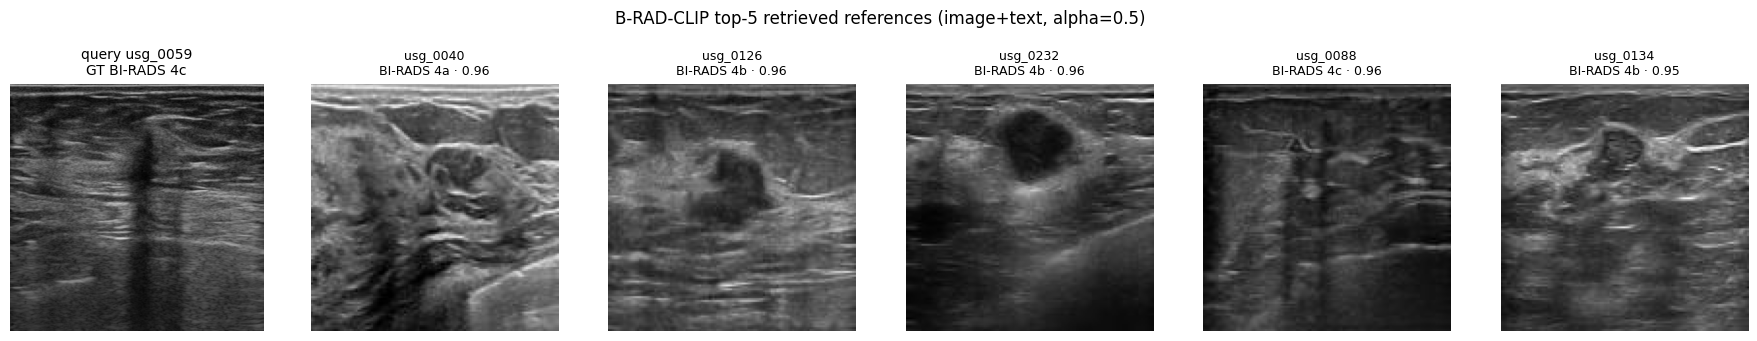

In [2]:
from brad_clip import BRADClip
from infer_retrieval import retrieve

# Image and report embeddings share one space (unpaired BI-RADS-supervised
# contrastive training), so retrieval fuses both similarities.
ALPHA = 0.5
clip_model = BRADClip(CLIP_CKPT, device=DEVICE, load_text=True)
query_emb = clip_model.embed_image(clip_model.load_image(IMG)).cpu().numpy()[0]
query_txt = clip_model.embed_text(TEXT).cpu().numpy()[0]
bank = np.load(BANK, allow_pickle=True)
refs = retrieve(query_emb, bank, topk=5, exclude_uid=s.uid,
                query_text_emb=query_txt, alpha=ALPHA)
for r in refs:
    print(f"  {r['uid']:>10}  BI-RADS {r['birads']:<3} {r['label']:<10} cos={r['similarity']:.3f}")

# Reference previews: full-resolution from BREAST_DATA_ROOT when available,
# otherwise the small JPEG thumbnails bundled with the reference bank.
_th = np.load(PKG / "B-RAD-CLIP/assets/reference_thumbs.npz")
_idx = {str(u): i for i, u in enumerate(_th["uid"])}


def ref_image(r):
    full = DATA_ROOT / r["image"]
    if full.exists():
        return cv2.cvtColor(cv2.imread(str(full)), cv2.COLOR_BGR2RGB)
    i = _idx.get(r["uid"])
    if i is None:
        return None
    blob = _th["thumb"][_th["offset"][i]:_th["offset"][i + 1]]
    return cv2.cvtColor(cv2.imdecode(blob, cv2.IMREAD_GRAYSCALE), cv2.COLOR_GRAY2RGB)


fig, ax = plt.subplots(1, 6, figsize=(18, 3.2))
ax[0].imshow(image_rgb); ax[0].set_title(f"query {s.uid}\nGT BI-RADS {GT_BIRADS}", fontsize=10)
for a, r in zip(ax[1:], refs):
    im = ref_image(r)
    if im is not None:
        a.imshow(im)
    else:
        a.text(0.5, 0.5, "preview unavailable", ha="center", va="center", fontsize=8, color="gray")
    a.set_title(f"{r['uid']}\nBI-RADS {r['birads']} | {r['similarity']:.2f}", fontsize=9)
for a in ax: a.axis("off")
plt.suptitle(f"B-RAD-CLIP top-5 retrieved references (image+text, alpha={ALPHA})", y=1.05); plt.tight_layout(); plt.show()

# Free the retrieval encoder: the segmentation step runs as a separate CUDA process.
import torch; del clip_model; torch.cuda.empty_cache()

## 2. B-RAD-Det: retrieval-guided lesion localization

The cases retrieved above act as support references for few-shot detection. Predicted box (**green**) vs. ground-truth box (**red**), with bbox Dice/IoU.


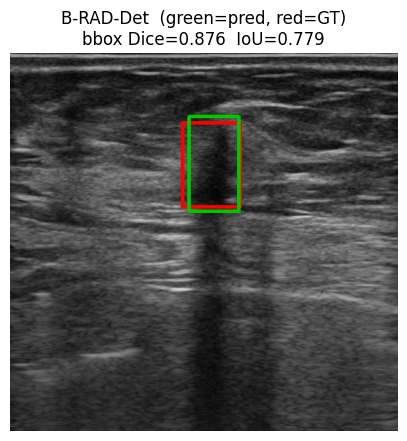

few-shot (4 references)   supports=['usg_0040', 'usg_0126', 'usg_0232', 'usg_0088']
pred_bbox=[251.2, 90.8, 321.1, 223.5]   gt_bbox=[242, 99, 323, 217]


In [3]:
# 4-shot supports: the top retrieved references, whose images ship with the demo.
support_refs = [f"{SAMPLES}/images/{r['uid']}.png:{SAMPLES}/masks/{r['uid']}_mask.png"
                for r in refs
                if (SAMPLES / f"images/{r['uid']}.png").exists()
                and (SAMPLES / f"masks/{r['uid']}_mask.png").exists()][:4]

det_json = OUT / f"{s.uid}_det.json"
subprocess.run([sys.executable, str(PKG / "B-RAD-Det/inference_single.py"),
                "--image", str(IMG), "--ckpt", DET_CKPT,
                "--references", *support_refs, "--out", str(det_json)],
               check=True, capture_output=True)
det = json.loads(det_json.read_text()); PRED_BBOX = det["bbox_xyxy"]

det_d, det_i = dice_iou(box_mask(PRED_BBOX, image_rgb.shape), box_mask(GT_BBOX, image_rgb.shape))
vis = image_rgb.copy()
cv2.rectangle(vis, (int(GT_BBOX[0]), int(GT_BBOX[1])), (int(GT_BBOX[2]), int(GT_BBOX[3])), (255, 0, 0), 3)
cv2.rectangle(vis, (int(PRED_BBOX[0]), int(PRED_BBOX[1])), (int(PRED_BBOX[2]), int(PRED_BBOX[3])), (0, 200, 0), 3)
plt.figure(figsize=(5, 5)); plt.imshow(vis); plt.axis("off")
plt.title(f"B-RAD-Det  (green=pred, red=GT)\nbbox Dice={det_d:.3f}  IoU={det_i:.3f}"); plt.show()
print(f"{det['mode']}   supports={[Path(r.split(':')[0]).stem for r in support_refs]}")
print(f"pred_bbox={ [round(v,1) for v in PRED_BBOX] }   gt_bbox={GT_BBOX}")


## 3. B-RAD-Seg: foundational segmentation

UltraSam is prompted with the detector box and produces a lesion mask (**red**), scored against the ground-truth mask (**yellow outline**). This cell runs in the `SEG_PY` environment.

usg_0059.png  Dice=0.8673  IoU=0.7657


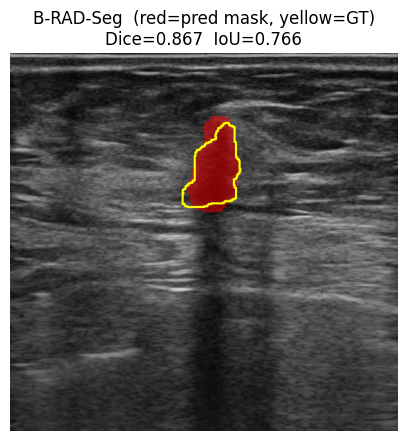

In [4]:
seg_png = OUT / f"{s.uid}_seg.png"
cmd = [SEG_PY, str(PKG / "B-RAD-Seg/infer_bbox.py"),
       "--image", str(IMG), "--bbox", ",".join(map(str, PRED_BBOX)),
       "--ckpt", SEG_CKPT, "--gt-mask", str(MASK),
       "--out-mask", str(seg_png), "--out", str(OUT / f"{s.uid}_seg.json")]
try:
    subprocess.run(cmd, check=True)
except (subprocess.CalledProcessError, FileNotFoundError):
    raise RuntimeError(
        f"B-RAD-Seg failed with SEG_PY={SEG_PY!r}. Point SEG_PY at the python of the "
        f"B-RAD-Seg environment (needs mmdet/mmcv/mmpretrain).") from None
seg = json.load(open(OUT / f"{s.uid}_seg.json"))
pred_mask = cv2.imread(str(seg_png), cv2.IMREAD_GRAYSCALE)

overlay = image_rgb.copy()
overlay[pred_mask > 0] = (0.5 * overlay[pred_mask > 0] + np.array([127, 0, 0])).astype(np.uint8)
for c in cv2.findContours((gt_mask > 0).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
    cv2.drawContours(overlay, [c], -1, (255, 255, 0), 2)
plt.figure(figsize=(5, 5)); plt.imshow(overlay); plt.axis("off")
plt.title(f"B-RAD-Seg  (red=pred mask, yellow=GT)\nDice={seg['dice']:.3f}  IoU={seg['iou']:.3f}"); plt.show()

## 4. B-RAD-FULL: region-aware BI-RADS classification

The predicted mask defines the ROI foveal bias; the fused image+text embedding drives the bundled 5-fold MLP ensemble over BI-RADS {2,3,4,5}.

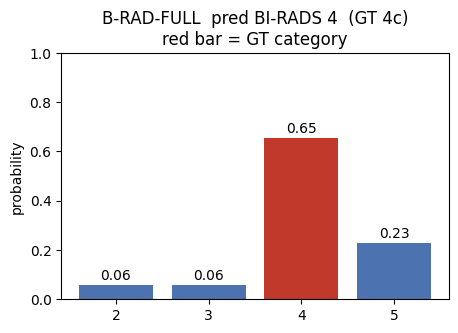

probabilities: {2: 0.0582, 3: 0.0589, 4: 0.6544, 5: 0.2285}


In [5]:
import importlib, infer_birads; importlib.reload(infer_birads)

import torch; torch.cuda.empty_cache()

full_model = infer_birads.BRADClip(FULL_CKPT, device=DEVICE, load_text=True)
text = TEXT
emb = infer_birads.embed(full_model, IMG, "concat", mask_path=seg_png, text=text)
probs = infer_birads.classify(emb, full_model.mlp_heads, infer_birads.MODE_CFG["concat"])
pred = infer_birads.BIRADS[int(probs.argmax())]

labels = [str(b) for b in infer_birads.BIRADS]
colors = ["#c0392b" if str(b) == GT_BIRADS[0] else "#4c72b0" for b in infer_birads.BIRADS]
plt.figure(figsize=(5, 3.2)); plt.bar(labels, probs, color=colors)
plt.ylabel("probability"); plt.ylim(0, 1)
plt.title(f"B-RAD-FULL  pred BI-RADS {pred}  (GT {GT_BIRADS})\nred bar = GT category")
for i, p in enumerate(probs): plt.text(i, p + 0.02, f"{p:.2f}", ha="center")
plt.show()
print("probabilities:", {b: round(float(p), 4) for b, p in zip(infer_birads.BIRADS, probs)})

## 5. Interpretability: where the model looked

Last-layer CLS attention over the image patches, taken from the same encoder pass
that produced the BI-RADS prediction. The white outline is the predicted lesion
mask; *lesion focus* is the attention density inside it relative to a uniform map
(1.0x = no localization).

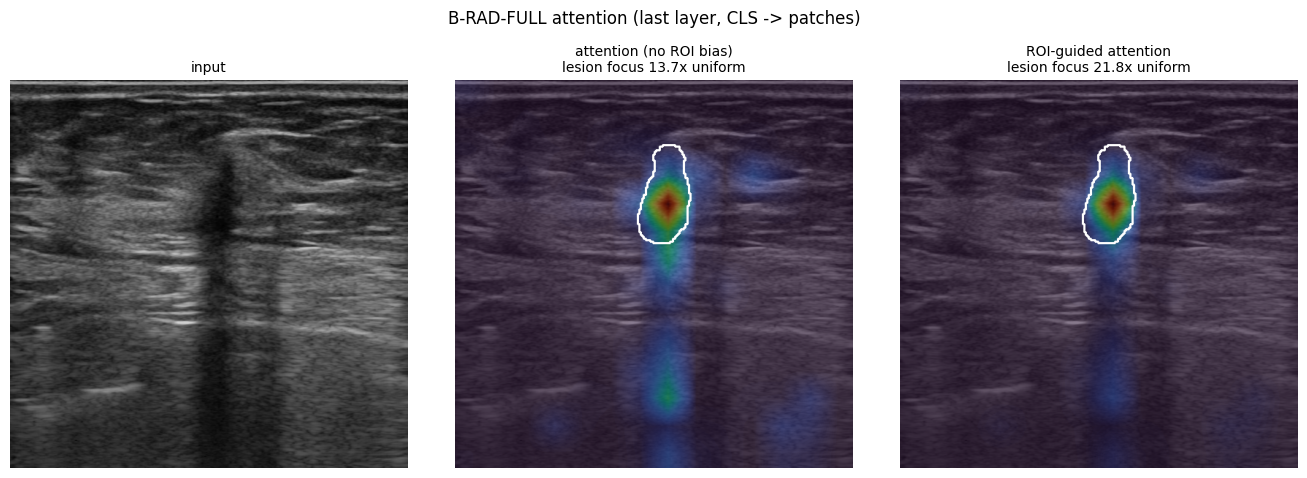

In [6]:
attn_in = full_model.load_image(IMG)
roi = infer_birads.roi_bias(full_model, seg_png)
attn_plain = full_model.attention_map(attn_in)[0]
attn_roi = full_model.attention_map(attn_in, attention_bias=roi)[0]

H, W = image_rgb.shape[:2]
turbo = plt.get_cmap("turbo")
lesion = pred_mask > 0


def _up(a):
    a = cv2.resize(np.clip(a, 0, None).astype(np.float32), (W, H), interpolation=cv2.INTER_LINEAR)
    return a


def heat(a):
    a = _up(a); a = (a - a.min()) / (a.max() - a.min() + 1e-9)
    return (0.55 * image_rgb + 0.45 * turbo(a)[..., :3] * 255).astype(np.uint8)


def focus(a):
    a = _up(a); a = a / (a.sum() + 1e-9)
    return a[lesion].sum() / max(lesion.mean(), 1e-9)


contours = cv2.findContours(lesion.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.6))
ax[0].imshow(image_rgb); ax[0].set_title("input", fontsize=10)
for a, m_, t_ in [(ax[1], attn_plain, "attention (no ROI bias)"),
                  (ax[2], attn_roi, "ROI-guided attention")]:
    v = heat(m_)
    cv2.drawContours(v, contours, -1, (255, 255, 255), 2)
    a.imshow(v); a.set_title(f"{t_}\nlesion focus {focus(m_):.1f}x uniform", fontsize=10)
for a in ax: a.axis("off")
plt.suptitle("B-RAD-FULL attention (last layer, CLS -> patches)", y=1.03)
plt.tight_layout(); plt.show()

## Summary

The four B-RAD modules run end-to-end from a single query image:
- BI-RADS-aware retrieval
- few-shot localization
- foundational segmentation
- region-aware BI-RADS classification.

`scripts/inference_full.sh` runs the same pipeline from the command line.